# 2 — Acesso e Inclusão: Etapa 5 (Descoberta de Features e Diagnóstico Espacial)

Este notebook lê exclusivamente os cinco arquivos `.gpkg` limpos em `data/3_done/` para:
1. **Bloco 5.1:** diagnosticar distribuições, assimetrias, extremos e separação de renda por `is_fcu` e `is_rural`.
2. **Bloco 5.2:** inspecionar mapas individuais de renda, densidade, idosos e subgrupos de equipamentos essenciais.
3. **Bloco 5.3:** testar duas famílias de candidatos espaciais em `EPSG:31982` (distância ao mais próximo e contagem em raios cicláveis de 1 km e 2 km) comparando centro, anel intermediário e periferia.
4. **Bloco 5.4:** avaliar redundâncias via correlação de Spearman e Pearson e fechar um catálogo enxuto de geradores recomendados (**sem atribuir pesos**).


In [1]:
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.spatial import cKDTree
from scipy.stats import mannwhitneyu

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DONE = ROOT / "data" / "3_done"
CRS_M = 31982  # SIRGAS 2000 / UTM 22S (metros)

setores = gpd.read_file(DONE / "setores_poa_limpo.gpkg", layer="setores_poa_limpo")
cnes = gpd.read_file(DONE / "cnes_poa_limpo.gpkg", layer="cnes_poa_limpo")
escolas = gpd.read_file(DONE / "escolas_poa_limpo.gpkg", layer="escolas_poa_limpo")
assistencia = gpd.read_file(DONE / "assistencia_poa_limpo.gpkg", layer="assistencia_poa_limpo")
fcu = gpd.read_file(DONE / "fcu_poa_contornos.gpkg", layer="fcu_poa_contornos")

# Versões métricas em EPSG:31982 para mapas sem distorção e cálculos de distância/raios
setores_m = setores.to_crs(CRS_M)
cnes_m = cnes.to_crs(CRS_M)
escolas_m = escolas.to_crs(CRS_M)
assistencia_m = assistencia.to_crs(CRS_M)
fcu_m = fcu.to_crs(CRS_M)

resumo_carga = pd.DataFrame([
    {"Camada": "setores_poa_limpo", "Linhas": len(setores), "Colunas": len(setores.columns), "CRS_origem": str(setores.crs)},
    {"Camada": "cnes_poa_limpo", "Linhas": len(cnes), "Colunas": len(cnes.columns), "CRS_origem": str(cnes.crs)},
    {"Camada": "escolas_poa_limpo", "Linhas": len(escolas), "Colunas": len(escolas.columns), "CRS_origem": str(escolas.crs)},
    {"Camada": "assistencia_poa_limpo", "Linhas": len(assistencia), "Colunas": len(assistencia.columns), "CRS_origem": str(assistencia.crs)},
    {"Camada": "fcu_poa_contornos", "Linhas": len(fcu), "Colunas": len(fcu.columns), "CRS_origem": str(fcu.crs)},
])
display(resumo_carga)


,Camada,Linhas,Colunas,CRS_origem
0,setores_poa_limpo,2730,17,EPSG:4674
1,cnes_poa_limpo,183,7,EPSG:4674
2,escolas_poa_limpo,809,12,EPSG:4674
3,assistencia_poa_limpo,35,6,EPSG:4674
4,fcu_poa_contornos,125,3,EPSG:4674


## Bloco 5.1 — Perfil estatístico e outliers do IBGE

Diagnóstico de escala, quartis, assimetria, outliers superiores e separação territorial (`is_fcu` e `is_rural`) nas variáveis contínuas dos setores censitários.


In [2]:
vars_ibge = ["V06006", "V06004", "pct_idosos", "densidade_hab_km2"]

perfil_rows = []
for col in vars_ibge:
    s = setores[col].dropna()
    q1, med, q3 = s.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    lim_sup = q3 + 1.5 * iqr
    perfil_rows.append({
        "Variavel": col,
        "N_validos": int(len(s)),
        "N_nulos": int(setores[col].isna().sum()),
        "Min": round(float(s.min()), 2),
        "P10": round(float(s.quantile(0.10)), 2),
        "Q1_25%": round(float(q1), 2),
        "Mediana": round(float(med), 2),
        "Q3_75%": round(float(q3), 2),
        "P95": round(float(s.quantile(0.95)), 2),
        "P99": round(float(s.quantile(0.99)), 2),
        "Max": round(float(s.max()), 2),
        "Media": round(float(s.mean()), 2),
        "Assimetria_skew": round(float(s.skew()), 2),
        "Outliers_acima_Q3_1.5IQR": int((s > lim_sup).sum()),
    })

print("== Perfil estatístico das variáveis contínuas do IBGE ==")
display(pd.DataFrame(perfil_rows))

# Razão média / mediana de renda intra-setor (mede assimetria interna da renda)
razao_renda = (setores["V06004"] / setores["V06006"].replace(0, np.nan)).dropna()
print(
    f"Razão V06004 / V06006 (média vs. mediana intra-setor): "
    f"mediana = {razao_renda.median():.2f}x | p90 = {razao_renda.quantile(0.90):.2f}x | máx = {razao_renda.max():.2f}x"
)

# Top 10 de densidade demográfica
print("\n== Top 10 setores por densidade_hab_km2 ==")
top10_dens = (
    setores.sort_values("densidade_hab_km2", ascending=False)
    [["CD_SETOR", "NM_BAIRRO", "CD_TIPO", "is_fcu", "v0001", "AREA_KM2", "densidade_hab_km2", "V06006", "pct_idosos"]]
    .head(10)
    .reset_index(drop=True)
)
display(top10_dens)

# Cruzamento de V06006 (e apoio) por is_fcu e is_rural
sobreposicao_fcu_rural = int((setores["is_fcu"] & setores["is_rural"]).sum())
print(f"\nSobreposição is_fcu & is_rural: {sobreposicao_fcu_rural} setores")

grupo_terr = np.where(
    setores["is_fcu"], "Urbano FCU",
    np.where(setores["is_rural"], "Rural", "Urbano não-FCU")
)
setores_tmp = setores.assign(grupo_territorial=grupo_terr)

cruzamento_renda = (
    setores_tmp.groupby("grupo_territorial")
    .agg(
        setores=("CD_SETOR", "count"),
        pop_total=("v0001", "sum"),
        n_v06006=("V06006", lambda s: int(s.notna().sum())),
        V06006_Q1=("V06006", lambda s: round(float(s.quantile(0.25)), 1)),
        V06006_mediana=("V06006", lambda s: round(float(s.median()), 1)),
        V06006_Q3=("V06006", lambda s: round(float(s.quantile(0.75)), 1)),
        V06006_media=("V06006", lambda s: round(float(s.mean()), 1)),
        pct_idosos_mediana=("pct_idosos", lambda s: round(float(s.median()), 1)),
        dens_mediana=("densidade_hab_km2", lambda s: round(float(s.median()), 1)),
    )
    .reindex(["Urbano não-FCU", "Urbano FCU", "Rural"])
)
print("\n== Cruzamento de V06006, idosos e densidade por grupo territorial ==")
display(cruzamento_renda)

# Teste de Mann-Whitney (FCU vs. Urbano não-FCU) e sobreposição interquartil
r_fcu = setores_tmp.loc[setores_tmp["grupo_territorial"] == "Urbano FCU", "V06006"].dropna()
r_urb = setores_tmp.loc[setores_tmp["grupo_territorial"] == "Urbano não-FCU", "V06006"].dropna()
stat_u, p_val = mannwhitneyu(r_fcu, r_urb, alternative="two-sided")
pct_urb_abaixo_q3_fcu = float((r_urb <= r_fcu.quantile(0.75)).mean() * 100)
print(
    f"Mann-Whitney V06006 (Urbano FCU vs. Urbano não-FCU): U={stat_u:,.0f}, p={p_val:.2e} | "
    f"mediana não-FCU é {r_urb.median() / r_fcu.median():.2f}x a mediana FCU | "
    f"{pct_urb_abaixo_q3_fcu:.1f}% dos setores urbanos não-FCU têm V06006 <= Q3 das FCUs (R$ {r_fcu.quantile(0.75):,.0f})"
)


== Perfil estatístico das variáveis contínuas do IBGE ==


,Variavel,N_validos,N_nulos,Min,P10,Q1_25%,Mediana,Q3_75%,P95,P99,Max,Media,Assimetria_skew,Outliers_acima_Q3_1.5IQR
0,V06006,2694,36,400.0,1212.00,1600.00,3000.00,5000.00,10000.00,15000.00,25000.00,3732.10,2.15,87
1,V06004,2694,36,500.0,1626.98,2197.15,3946.13,6697.69,12810.26,19837.58,49759.69,5117.31,2.51,116
2,pct_idosos,2656,74,0.0,10.91,16.67,24.36,30.48,37.76,43.89,51.95,23.63,-0.06,1
3,densidade_hab_km2,2730,0,0.0,1996.35,5025.39,9397.34,16384.51,39243.97,74842.08,491771.68,13525.67,9.85,198


Razão V06004 / V06006 (média vs. mediana intra-setor): mediana = 1.33x | p90 = 1.59x | máx = 6.77x

== Top 10 setores por densidade_hab_km2 ==


,CD_SETOR,NM_BAIRRO,CD_TIPO,is_fcu,v0001,AREA_KM2,densidade_hab_km2,V06006,pct_idosos
0,431490205000286,Bom Jesus,0,False,288,0.000586,491771.676680,1256.0,15.625000
1,431490205000106,Cidade Baixa,0,False,243,0.001349,180182.021700,2800.0,24.279835
2,431490205000038,Centro Histórico,0,False,196,0.001210,161947.916227,2500.0,20.918367
3,431490205001931,Sarandi,0,False,472,0.003549,132980.505263,3300.0,27.330508
4,431490205000086,Centro Histórico,0,False,257,0.001991,129107.327288,4750.0,19.066148
5,431490205002347,Vila Ipiranga,0,False,435,0.003498,124355.407613,5350.0,16.091954
6,431490205001930,Sarandi,0,False,461,0.003769,122298.541874,3000.0,29.501085
7,431490205000070,Centro Histórico,0,False,278,0.002414,115143.430268,7000.0,34.892086
8,431490205000009,Centro Histórico,0,False,261,0.002303,113321.957022,3500.0,22.988506
9,431490205000733,Santa Tereza,0,False,378,0.003575,105740.944218,3800.0,22.486772



Sobreposição is_fcu & is_rural: 0 setores

== Cruzamento de V06006, idosos e densidade por grupo territorial ==


,setores,pop_total,n_v06006,V06006_Q1,V06006_mediana,V06006_Q3,V06006_media,pct_idosos_mediana,dens_mediana
grupo_territorial,,,,,,,,,
Urbano não-FCU,2386,1152108,2354,2000.0,3000.0,5000.0,4076.5,25.7,8945.5
Urbano FCU,323,175519,322,1212.0,1250.0,1500.0,1342.8,12.4,13207.3
Rural,21,2417,18,1212.0,1375.0,1864.4,1433.6,24.3,69.6


Mann-Whitney V06006 (Urbano FCU vs. Urbano não-FCU): U=52,175, p=1.16e-139 | mediana não-FCU é 2.40x a mediana FCU | 13.7% dos setores urbanos não-FCU têm V06006 <= Q3 das FCUs (R$ 1,500)


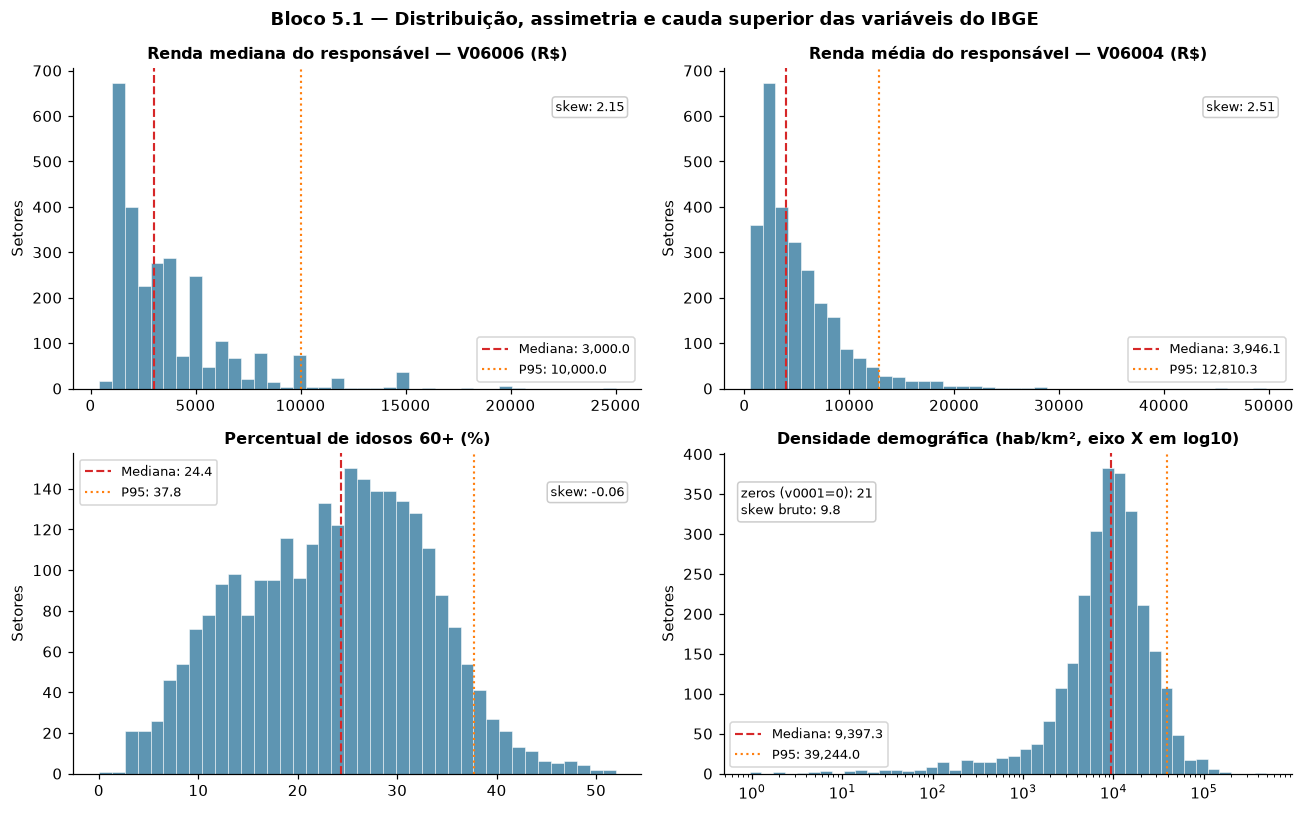

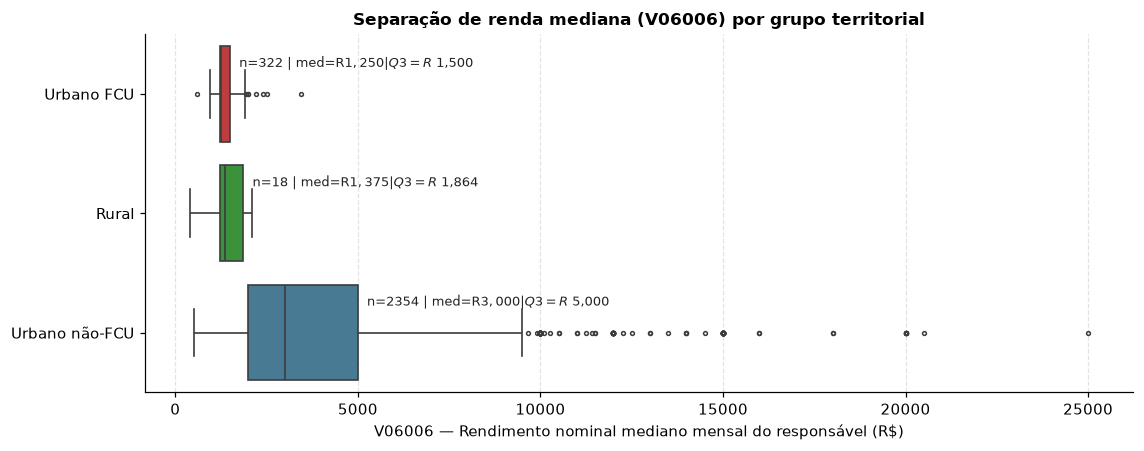

In [3]:
# Gráficos úteis do Bloco 5.1:
# (1) Distribuições das 4 variáveis contínuas (com mediana e p95) para avaliar assimetria/escala
# (2) Comparação direta de V06006 por grupo territorial (Urbano não-FCU vs. FCU vs. Rural)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
specs = [
    ("V06006", "Renda mediana do responsável — V06006 (R$)", False),
    ("V06004", "Renda média do responsável — V06004 (R$)", False),
    ("pct_idosos", "Percentual de idosos 60+ (%)", False),
    ("densidade_hab_km2", "Densidade demográfica (hab/km², eixo X em log10)", True),
]

for ax, (col, titulo, use_log) in zip(axes.flat, specs):
    s = setores[col].dropna()
    if use_log:
        s_plot = s[s > 0]
        bins = np.logspace(np.log10(s_plot.min()), np.log10(s_plot.max()), 45)
        ax.hist(s_plot, bins=bins, color="#3b7ea1", alpha=0.82, edgecolor="white", linewidth=0.4)
        ax.set_xscale("log")
        med, p95 = s.median(), s.quantile(0.95)
        ax.text(0.03, 0.90, f"zeros (v0001=0): {int((s == 0).sum())}\nskew bruto: {s.skew():.1f}", transform=ax.transAxes, fontsize=8.5, va="top", bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#cccccc"))
    else:
        ax.hist(s, bins=40, color="#3b7ea1", alpha=0.82, edgecolor="white", linewidth=0.4)
        med, p95 = s.median(), s.quantile(0.95)
        ax.text(0.97, 0.90, f"skew: {s.skew():.2f}", transform=ax.transAxes, fontsize=8.5, ha="right", va="top", bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#cccccc"))
    ax.axvline(med, color="#d62728", linestyle="--", linewidth=1.4, label=f"Mediana: {med:,.1f}")
    ax.axvline(p95, color="#ff7f0e", linestyle=":", linewidth=1.4, label=f"P95: {p95:,.1f}")
    ax.set_title(titulo, fontsize=10.5, fontweight="bold")
    ax.set_ylabel("Setores")
    ax.legend(fontsize=8.5, frameon=True)

fig.suptitle("Bloco 5.1 — Distribuição, assimetria e cauda superior das variáveis do IBGE", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

# Boxplot de separação de V06006 por grupo territorial
ordem = ["Urbano FCU", "Rural", "Urbano não-FCU"]
paleta = {"Urbano FCU": "#d62728", "Rural": "#2ca02c", "Urbano não-FCU": "#3b7ea1"}

fig, ax = plt.subplots(figsize=(10.5, 4.2))
sns.boxplot(
    data=setores_tmp.dropna(subset=["V06006"]),
    y="grupo_territorial",
    x="V06006",
    order=ordem,
    palette=paleta,
    hue="grupo_territorial",
    legend=False,
    fliersize=2.5,
    linewidth=1.1,
    ax=ax,
)
for i, g in enumerate(ordem):
    sub = setores_tmp.loc[setores_tmp["grupo_territorial"] == g, "V06006"].dropna()
    ax.text(
        sub.quantile(0.75) + 250, i - 0.25,
        f"n={len(sub)} | med=R$ {sub.median():,.0f} | Q3=R$ {sub.quantile(0.75):,.0f}",
        fontsize=8.5, color="#222222", va="center",
    )
ax.set_title("Separação de renda mediana (V06006) por grupo territorial", fontsize=11, fontweight="bold")
ax.set_xlabel("V06006 — Rendimento nominal mediano mensal do responsável (R$)")
ax.set_ylabel("")
ax.grid(axis="x", linestyle="--", alpha=0.35)
plt.tight_layout()
plt.show()


## Bloco 5.2 — Mapas diagnósticos individuais

Inspeção visual em `EPSG:31982` da distribuição espacial das variáveis censitárias (quintis com nulos explícitos em cinza neutro) e dos subgrupos de equipamentos essenciais limpos no Passo 4.


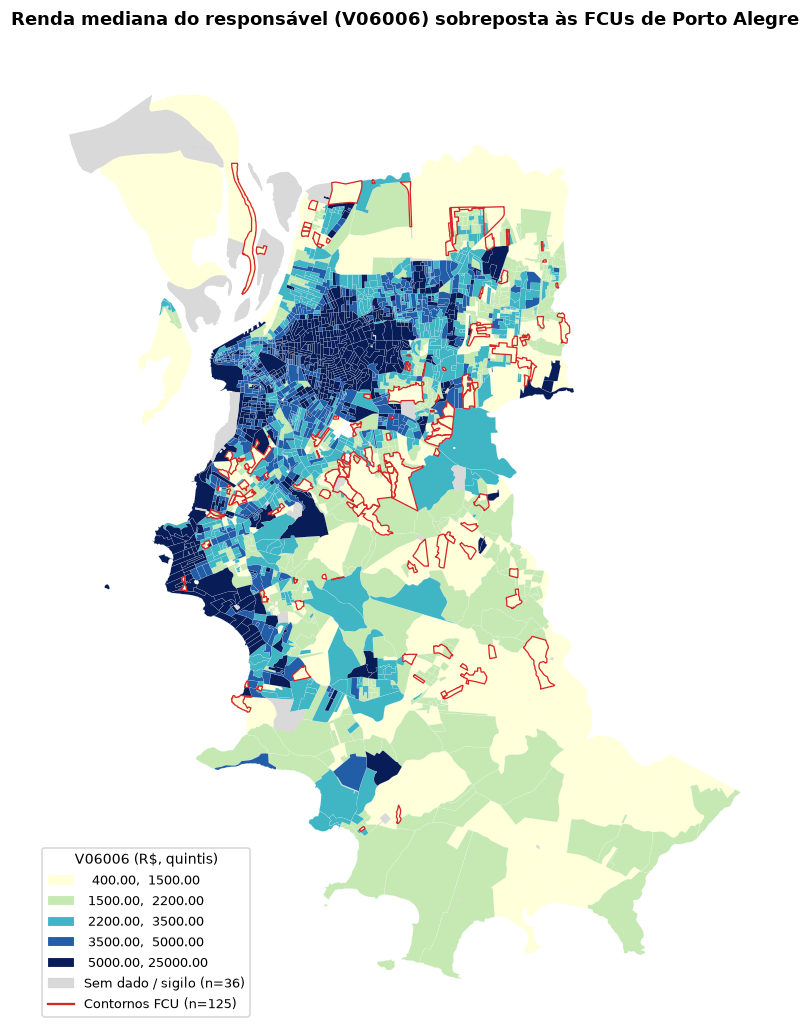

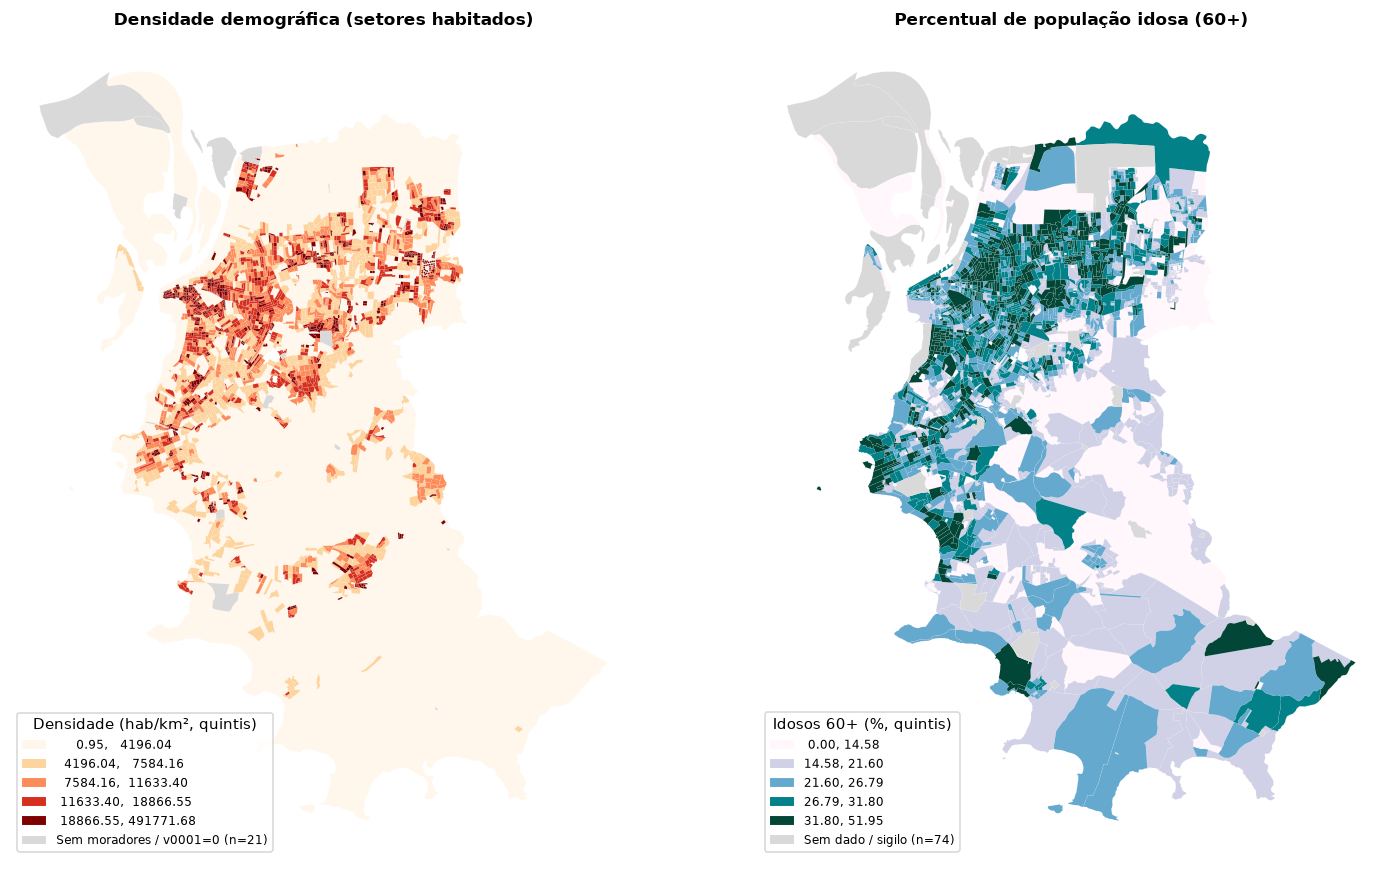

In [4]:
# Mapa 1: V06006 em quintis + 36 nulos em cinza neutro + contornos das 125 FCUs
fig, ax = plt.subplots(figsize=(9, 9.5))
setores_m.plot(
    column="V06006",
    scheme="quantiles",
    k=5,
    cmap="YlGnBu",
    linewidth=0.08,
    edgecolor="#ffffff",
    legend=True,
    missing_kwds={"color": "#d9d9d9", "edgecolor": "#bbbbbb", "label": f"Sem dado / sigilo (n={int(setores_m['V06006'].isna().sum())})"},
    legend_kwds={"title": "V06006 (R$, quintis)", "loc": "lower left", "frameon": True, "fontsize": 8.5},
    ax=ax,
)
fcu_m.boundary.plot(ax=ax, color="#d62728", linewidth=0.85, label=f"Contornos FCU (n={len(fcu_m)})")
# Adiciona entrada da legenda para FCU
handles, labels = ax.get_legend().legend_handles, [t.get_text() for t in ax.get_legend().get_texts()]
from matplotlib.lines import Line2D
handles.append(Line2D([0], [0], color="#d62728", lw=1.5))
labels.append(f"Contornos FCU (n={len(fcu_m)})")
ax.legend(handles, labels, title="V06006 (R$, quintis)", loc="lower left", frameon=True, fontsize=8.5, title_fontsize=9)
ax.set_title("Renda mediana do responsável (V06006) sobreposta às FCUs de Porto Alegre", fontsize=11.5, fontweight="bold")
ax.set_axis_off()
plt.tight_layout()
plt.show()

# Mapa 2: Densidade demográfica e Percentual de idosos (60+) lado a lado em quintis
fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# Densidade: separa os 21 setores com v0001 == 0 em cinza para os quintis representarem áreas habitadas
dens_hab = setores_m["densidade_hab_km2"].where(setores_m["v0001"] > 0)
setores_m.assign(_dens_hab=dens_hab).plot(
    column="_dens_hab",
    scheme="quantiles",
    k=5,
    cmap="OrRd",
    linewidth=0.05,
    edgecolor="#ffffff",
    legend=True,
    missing_kwds={"color": "#d9d9d9", "label": f"Sem moradores / v0001=0 (n={int((setores_m['v0001'] == 0).sum())})"},
    legend_kwds={"title": "Densidade (hab/km², quintis)", "loc": "lower left", "fontsize": 8},
    ax=axes[0],
)
axes[0].set_title("Densidade demográfica (setores habitados)", fontsize=11, fontweight="bold")
axes[0].set_axis_off()

setores_m.plot(
    column="pct_idosos",
    scheme="quantiles",
    k=5,
    cmap="PuBuGn",
    linewidth=0.05,
    edgecolor="#ffffff",
    legend=True,
    missing_kwds={"color": "#d9d9d9", "label": f"Sem dado / sigilo (n={int(setores_m['pct_idosos'].isna().sum())})"},
    legend_kwds={"title": "Idosos 60+ (%, quintis)", "loc": "lower left", "fontsize": 8},
    ax=axes[1],
)
axes[1].set_title("Percentual de população idosa (60+)", fontsize=11, fontweight="bold")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()


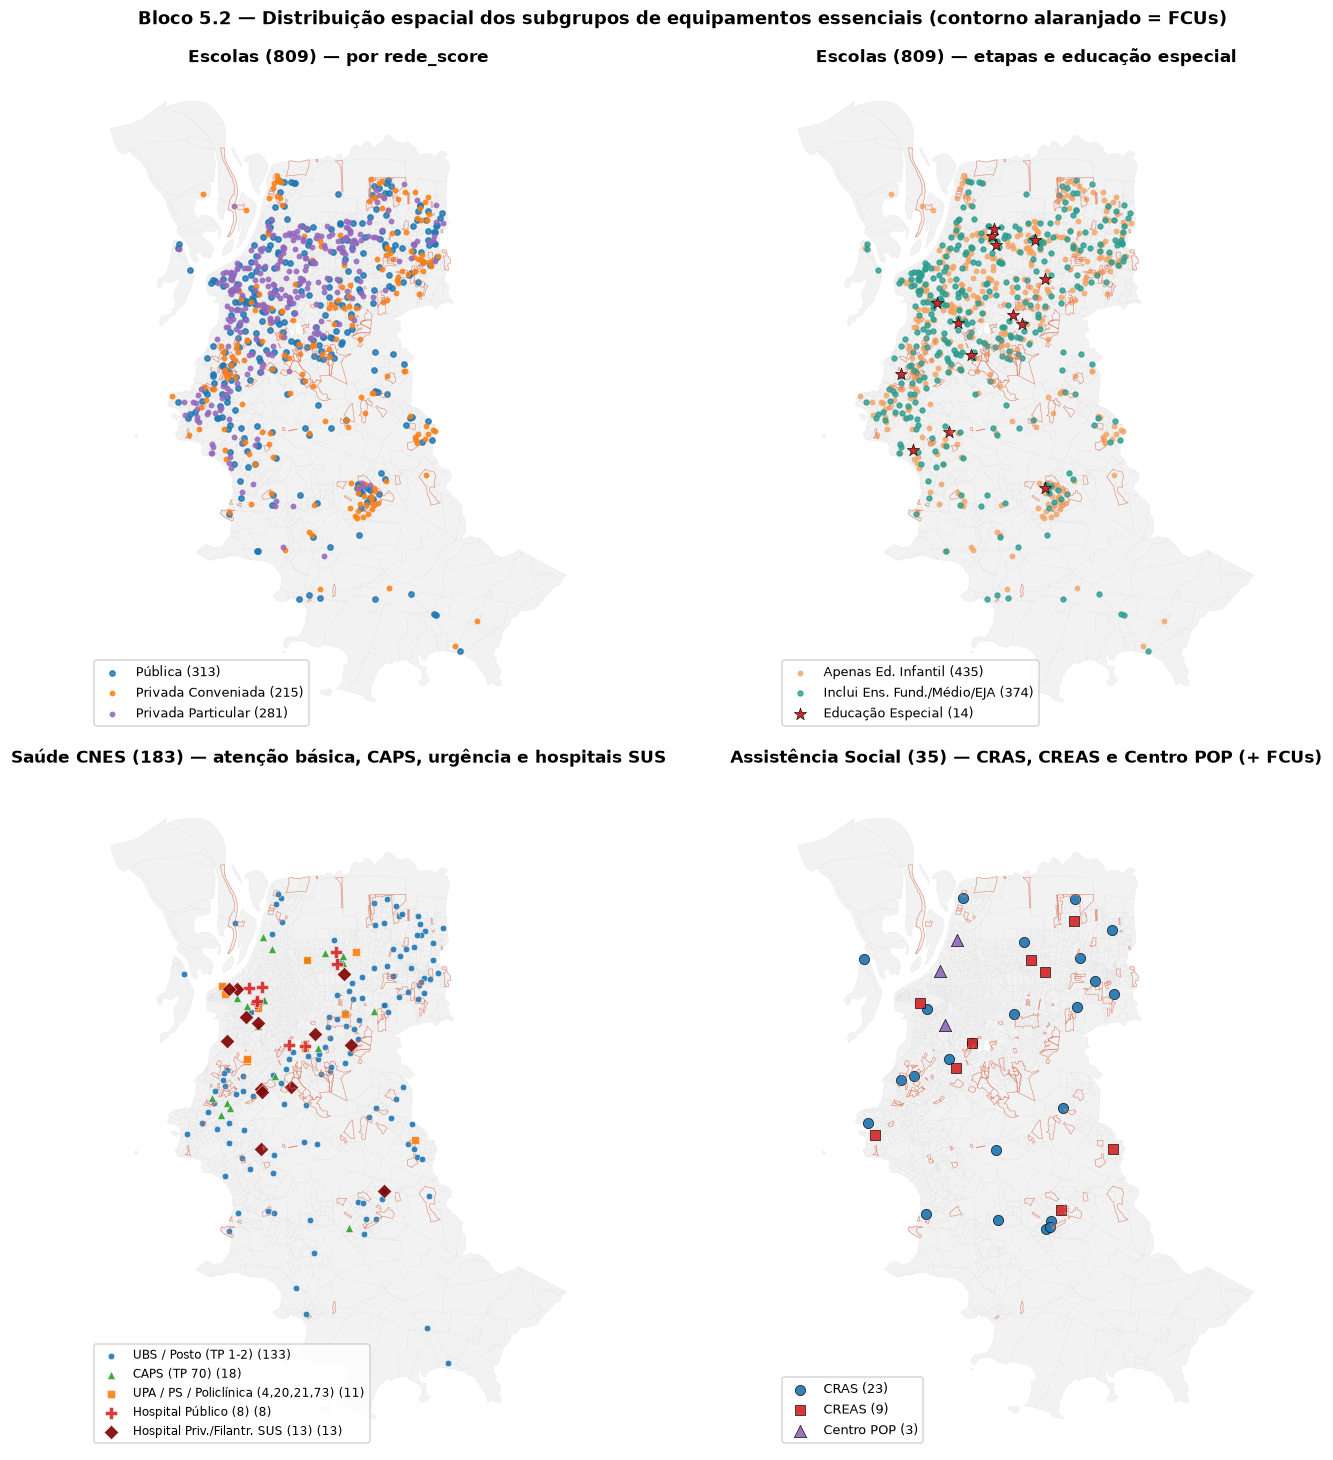

In [5]:
# Mapas diagnósticos dos pontos de serviço separando os subgrupos limpos (painel 2x2)
fig, axes = plt.subplots(2, 2, figsize=(14, 13.5))

def fundo_poa(ax):
    setores_m.plot(ax=ax, color="#f2f2f2", edgecolor="#dcdcdc", linewidth=0.15)
    fcu_m.boundary.plot(ax=ax, color="#e07a5f", linewidth=0.45, alpha=0.7)
    ax.set_axis_off()

# (1) Escolas por rede_score
ax = axes[0, 0]
fundo_poa(ax)
cores_rede = {"Pública": "#1f77b4", "Privada Conveniada": "#ff7f0e", "Privada Particular": "#9467bd"}
for rede, cor in cores_rede.items():
    sub = escolas_m.loc[escolas_m["rede_score"] == rede]
    sub.plot(ax=ax, color=cor, markersize=12 if rede == "Pública" else 8, alpha=0.82, label=f"{rede} ({len(sub)})")
ax.set_title("Escolas (809) — por rede_score", fontsize=11, fontweight="bold")
ax.legend(loc="lower left", fontsize=8.5, frameon=True)

# (2) Escolas por etapa (apenas infantil vs. outras etapas) + educação especial
ax = axes[0, 1]
fundo_poa(ax)
so_inf = escolas_m.loc[escolas_m["is_apenas_educacao_infantil"]]
outras = escolas_m.loc[~escolas_m["is_apenas_educacao_infantil"]]
espec = escolas_m.loc[escolas_m["is_educacao_especial"]]
so_inf.plot(ax=ax, color="#f4a261", markersize=8, alpha=0.75, label=f"Apenas Ed. Infantil ({len(so_inf)})")
outras.plot(ax=ax, color="#2a9d8f", markersize=10, alpha=0.8, label=f"Inclui Ens. Fund./Médio/EJA ({len(outras)})")
espec.plot(ax=ax, color="#d62728", marker="*", markersize=70, edgecolor="black", linewidth=0.4, label=f"Educação Especial ({len(espec)})")
ax.set_title("Escolas (809) — etapas e educação especial", fontsize=11, fontweight="bold")
ax.legend(loc="lower left", fontsize=8.5, frameon=True)

# (3) Saúde CNES (183) separando tipo e tipo_hospital_sus
ax = axes[1, 0]
fundo_poa(ax)
cnes_grupos = [
    ("UBS / Posto (TP 1-2)", cnes_m["TP_UNIDADE"].isin(["1", "2"]), "#1f77b4", "o", 18),
    ("CAPS (TP 70)", cnes_m["TP_UNIDADE"].eq("70"), "#2ca02c", "^", 28),
    ("UPA / PS / Policlínica (4,20,21,73)", cnes_m["TP_UNIDADE"].isin(["4", "20", "21", "73"]), "#ff7f0e", "s", 26),
    ("Hospital Público (8)", cnes_m["tipo_hospital_sus"].eq("publico"), "#d62728", "P", 65),
    ("Hospital Priv./Filantr. SUS (13)", cnes_m["tipo_hospital_sus"].eq("privado_filantropico_sus"), "#7f0000", "D", 45),
]
for label, mask, cor, mk, sz in cnes_grupos:
    sub = cnes_m.loc[mask]
    sub.plot(ax=ax, color=cor, marker=mk, markersize=sz, edgecolor="white", linewidth=0.35, alpha=0.9, label=f"{label} ({len(sub)})")
ax.set_title("Saúde CNES (183) — atenção básica, CAPS, urgência e hospitais SUS", fontsize=11, fontweight="bold")
ax.legend(loc="lower left", fontsize=8, frameon=True)

# (4) Assistência Social (35) por categoria sobreposto às FCUs
ax = axes[1, 1]
fundo_poa(ax)
assist_specs = [
    ("CRAS", "#1f77b4", "o", 45),
    ("CREAS", "#d62728", "s", 50),
    ("Centro POP", "#9467bd", "^", 65),
]
for cat, cor, mk, sz in assist_specs:
    sub = assistencia_m.loc[assistencia_m["categoria"] == cat]
    sub.plot(ax=ax, color=cor, marker=mk, markersize=sz, edgecolor="black", linewidth=0.45, alpha=0.92, label=f"{cat} ({len(sub)})")
ax.set_title("Assistência Social (35) — CRAS, CREAS e Centro POP (+ FCUs)", fontsize=11, fontweight="bold")
ax.legend(loc="lower left", fontsize=8.5, frameon=True)

fig.suptitle("Bloco 5.2 — Distribuição espacial dos subgrupos de equipamentos essenciais (contorno alaranjado = FCUs)", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## Bloco 5.3 — Teste de candidatos espaciais em `EPSG:31982`

Para cada setor censitário (usando `representative_point()` — sempre contido dentro do polígono), calculamos duas famílias de indicadores em metros:
1. **Distância euclidiana até o serviço mais próximo** (`dist_<grupo>_m`).
2. **Contagem de equipamentos em raios cicláveis de 1 km e 2 km** (`n_<grupo>_1km`, `n_<grupo>_2km`).

Em seguida, comparamos o comportamento dessas famílias entre **Anel Central** (≤ 4 km do Centro Histórico), **Anel Intermediário** (4–10 km) e **Anel Periférico** (> 10 km).


In [6]:
# Pontos representativos dos setores em EPSG:31982 (sempre internos ao polígono)
pts_setores = setores_m.geometry.representative_point()
coords_setores = np.column_stack([pts_setores.x.to_numpy(), pts_setores.y.to_numpy()])

# Referência do Centro Histórico para estratificar em anéis radiais (centro / intermediário / periferia)
centro_geom = setores_m.loc[setores_m["NM_BAIRRO"] == "Centro Histórico"].union_all().representative_point()
dist_centro_km = np.hypot(coords_setores[:, 0] - centro_geom.x, coords_setores[:, 1] - centro_geom.y) / 1000.0

anel = pd.cut(
    dist_centro_km,
    bins=[-0.001, 4.0, 10.0, np.inf],
    labels=["Central (<=4 km)", "Intermediário (4-10 km)", "Periférico (>10 km)"],
)

# Subgrupos de equipamentos a testar
grupos_servicos = {
    "saude_total": cnes_m,
    "ubs": cnes_m.loc[cnes_m["TP_UNIDADE"].isin(["1", "2"])],
    "hosp_urg": cnes_m.loc[cnes_m["TP_UNIDADE"].isin(["5", "7", "20", "21", "73"])],
    "caps": cnes_m.loc[cnes_m["TP_UNIDADE"].eq("70")],
    "esc_pub": escolas_m.loc[escolas_m["rede_score"].eq("Pública")],
    "esc_pub_conv": escolas_m.loc[escolas_m["rede_score"].isin(["Pública", "Privada Conveniada"])],
    "esc_nao_so_inf": escolas_m.loc[~escolas_m["is_apenas_educacao_infantil"]],
    "esc_todas": escolas_m,
    "assist": assistencia_m,
}

metricas = pd.DataFrame({
    "CD_SETOR": setores_m["CD_SETOR"].to_numpy(),
    "NM_BAIRRO": setores_m["NM_BAIRRO"].to_numpy(),
    "dist_centro_km": np.round(dist_centro_km, 2),
    "anel": anel,
})

for nome, gdf_pts in grupos_servicos.items():
    xy = np.column_stack([gdf_pts.geometry.x.to_numpy(), gdf_pts.geometry.y.to_numpy()])
    tree = cKDTree(xy)
    dists, _ = tree.query(coords_setores, k=1)
    metricas[f"dist_{nome}_m"] = np.round(dists, 1)
    metricas[f"n_{nome}_1km"] = [len(idx) for idx in tree.query_ball_point(coords_setores, r=1000.0)]
    metricas[f"n_{nome}_2km"] = [len(idx) for idx in tree.query_ball_point(coords_setores, r=2000.0)]

# Conferência dos anéis territoriais
resumo_aneis = (
    metricas.merge(setores[["CD_SETOR", "v0001", "V06006", "is_fcu", "is_rural"]], on="CD_SETOR")
    .groupby("anel", observed=False)
    .agg(
        setores=("CD_SETOR", "count"),
        pop_total=("v0001", "sum"),
        pct_fcu=("is_fcu", lambda s: round(float(s.mean() * 100), 1)),
        V06006_mediana=("V06006", lambda s: round(float(s.median()), 0)),
        bairros_tipicos=("NM_BAIRRO", lambda s: ", ".join(s.value_counts().head(3).index)),
    )
)
print("== Estratificação territorial em anéis radiais (a partir do Centro Histórico) ==")
display(resumo_aneis)

# Comparação entre famílias (distância vs. contagem 1 km vs. contagem 2 km) por anel
grupos_destaque = ["ubs", "hosp_urg", "caps", "esc_pub", "esc_pub_conv", "assist"]
comp_rows = []
for g in grupos_destaque:
    for anel_nome, sub in metricas.groupby("anel", observed=False):
        comp_rows.append({
            "Servico": g,
            "Anel": anel_nome,
            "dist_mediana_m": round(float(sub[f"dist_{g}_m"].median()), 0),
            "dist_p90_m": round(float(sub[f"dist_{g}_m"].quantile(0.90)), 0),
            "n_1km_mediana": round(float(sub[f"n_{g}_1km"].median()), 1),
            "pct_zero_1km": round(float((sub[f"n_{g}_1km"] == 0).mean() * 100), 1),
            "n_2km_mediana": round(float(sub[f"n_{g}_2km"].median()), 1),
            "pct_zero_2km": round(float((sub[f"n_{g}_2km"] == 0).mean() * 100), 1),
        })

comp_aneis = pd.DataFrame(comp_rows)
print("\n== Comportamento das duas famílias de métricas (Distância vs. Contagem 1 km / 2 km) por anel ==")
display(comp_aneis)


== Estratificação territorial em anéis radiais (a partir do Centro Histórico) ==


,setores,pop_total,pct_fcu,V06006_mediana,bairros_tipicos
anel,,,,,
Central (<=4 km),583,222979,0.3,5000.0,"Centro Histórico, Menino-Deus, Santana"
Intermediário (4-10 km),1301,627479,15.8,3000.0,"Partenon, Cristal, Santa Tereza"
Periférico (>10 km),846,479586,13.6,1800.0,"Restinga, Lomba do Pinheiro, Mário Quintana"



== Comportamento das duas famílias de métricas (Distância vs. Contagem 1 km / 2 km) por anel ==


,Servico,Anel,dist_mediana_m,dist_p90_m,n_1km_mediana,pct_zero_1km,n_2km_mediana,pct_zero_2km
0,ubs,Central (<=4 km),1120.0,1768.0,0.0,60.2,2.0,2.4
1,ubs,Intermediário (4-10 km),554.0,1313.0,2.0,19.5,7.0,2.2
2,ubs,Periférico (>10 km),473.0,1307.0,2.0,18.2,6.0,4.7
3,hosp_urg,Central (<=4 km),690.0,1725.0,1.0,30.2,6.0,5.5
4,hosp_urg,Intermediário (4-10 km),1304.0,3596.0,0.0,64.6,2.0,30.1
5,hosp_urg,Periférico (>10 km),3542.0,5741.0,0.0,93.5,0.0,82.2
6,caps,Central (<=4 km),921.0,1672.0,1.0,43.4,3.0,4.3
7,caps,Intermediário (4-10 km),1487.0,2432.0,0.0,71.1,1.0,24.8
8,caps,Periférico (>10 km),3945.0,6462.0,0.0,97.4,0.0,88.4
9,esc_pub,Central (<=4 km),274.0,534.0,7.0,1.0,26.0,0.2


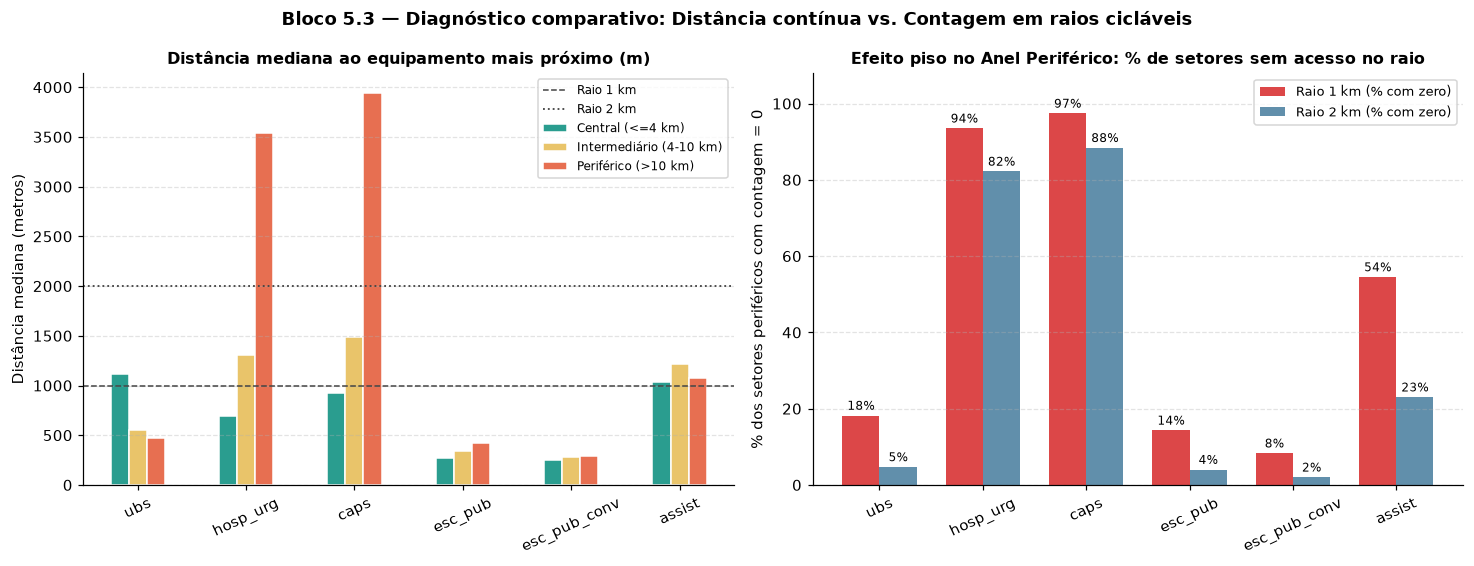

In [7]:
# Gráfico útil do Bloco 5.3:
# (1) Distância mediana ao serviço mais próximo por anel (evidencia gradiente centro-periferia)
# (2) Percentual de setores com 0 equipamentos no raio de 1 km vs. 2 km (evidencia efeito piso/saturação)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

# Painel A: Distância mediana (m) por serviço e anel
piv_dist = comp_aneis.pivot(index="Servico", columns="Anel", values="dist_mediana_m").loc[grupos_destaque]
piv_dist.plot(kind="bar", ax=axes[0], color=["#2a9d8f", "#e9c46a", "#e76f51"], edgecolor="white")
axes[0].axhline(1000, color="#444444", linestyle="--", linewidth=1, label="Raio 1 km")
axes[0].axhline(2000, color="#444444", linestyle=":", linewidth=1.2, label="Raio 2 km")
axes[0].set_title("Distância mediana ao equipamento mais próximo (m)", fontsize=10.5, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Distância mediana (metros)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", linestyle="--", alpha=0.35)
axes[0].legend(fontsize=8, frameon=True)

# Painel B: % de setores com contagem == 0 no anel periférico (1 km vs. 2 km)
perif = comp_aneis.loc[comp_aneis["Anel"] == "Periférico (>10 km)"].set_index("Servico").loc[grupos_destaque]
x = np.arange(len(grupos_destaque))
w = 0.36
axes[1].bar(x - w/2, perif["pct_zero_1km"], width=w, color="#d62728", alpha=0.85, label="Raio 1 km (% com zero)")
axes[1].bar(x + w/2, perif["pct_zero_2km"], width=w, color="#457b9d", alpha=0.85, label="Raio 2 km (% com zero)")
for i, g in enumerate(grupos_destaque):
    axes[1].text(i - w/2, perif.loc[g, "pct_zero_1km"] + 1.5, f"{perif.loc[g, 'pct_zero_1km']:.0f}%", ha="center", fontsize=8)
    axes[1].text(i + w/2, perif.loc[g, "pct_zero_2km"] + 1.5, f"{perif.loc[g, 'pct_zero_2km']:.0f}%", ha="center", fontsize=8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(grupos_destaque, rotation=25)
axes[1].set_ylim(0, 108)
axes[1].set_title("Efeito piso no Anel Periférico: % de setores sem acesso no raio", fontsize=10.5, fontweight="bold")
axes[1].set_ylabel("% dos setores periféricos com contagem = 0")
axes[1].grid(axis="y", linestyle="--", alpha=0.35)
axes[1].legend(fontsize=8.5, frameon=True)

fig.suptitle("Bloco 5.3 — Diagnóstico comparativo: Distância contínua vs. Contagem em raios cicláveis", fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()


## Bloco 5.4 — Correlação (Spearman e Pearson) e catálogo de geradores

Análise de colinearidade entre todos os candidatos demográficos e espaciais para cortar variáveis redundantes e fechar o catálogo recomendado de geradores (**sem pesos**).


== Pares com forte redundância (|Spearman| >= 0.80): 16 pares ==


,Var_A,Var_B,Spearman,Pearson
0,V06006,V06004,0.976,0.925
1,n_esc_nao_so_inf_2km,n_esc_todas_2km,0.941,0.942
2,n_esc_nao_so_inf_1km,n_esc_todas_1km,0.880,0.862
3,dist_hosp_urg_m,n_hosp_urg_2km,-0.872,-0.601
4,n_esc_pub_2km,n_esc_nao_so_inf_2km,0.871,0.899
5,dist_caps_m,n_caps_2km,-0.864,-0.644
6,n_esc_pub_2km,n_esc_pub_conv_2km,0.861,0.879
7,dist_assist_m,n_assist_1km,-0.849,-0.497
8,dist_esc_pub_m,dist_esc_nao_so_inf_m,0.847,0.973
9,n_esc_pub_2km,n_esc_todas_2km,0.839,0.893


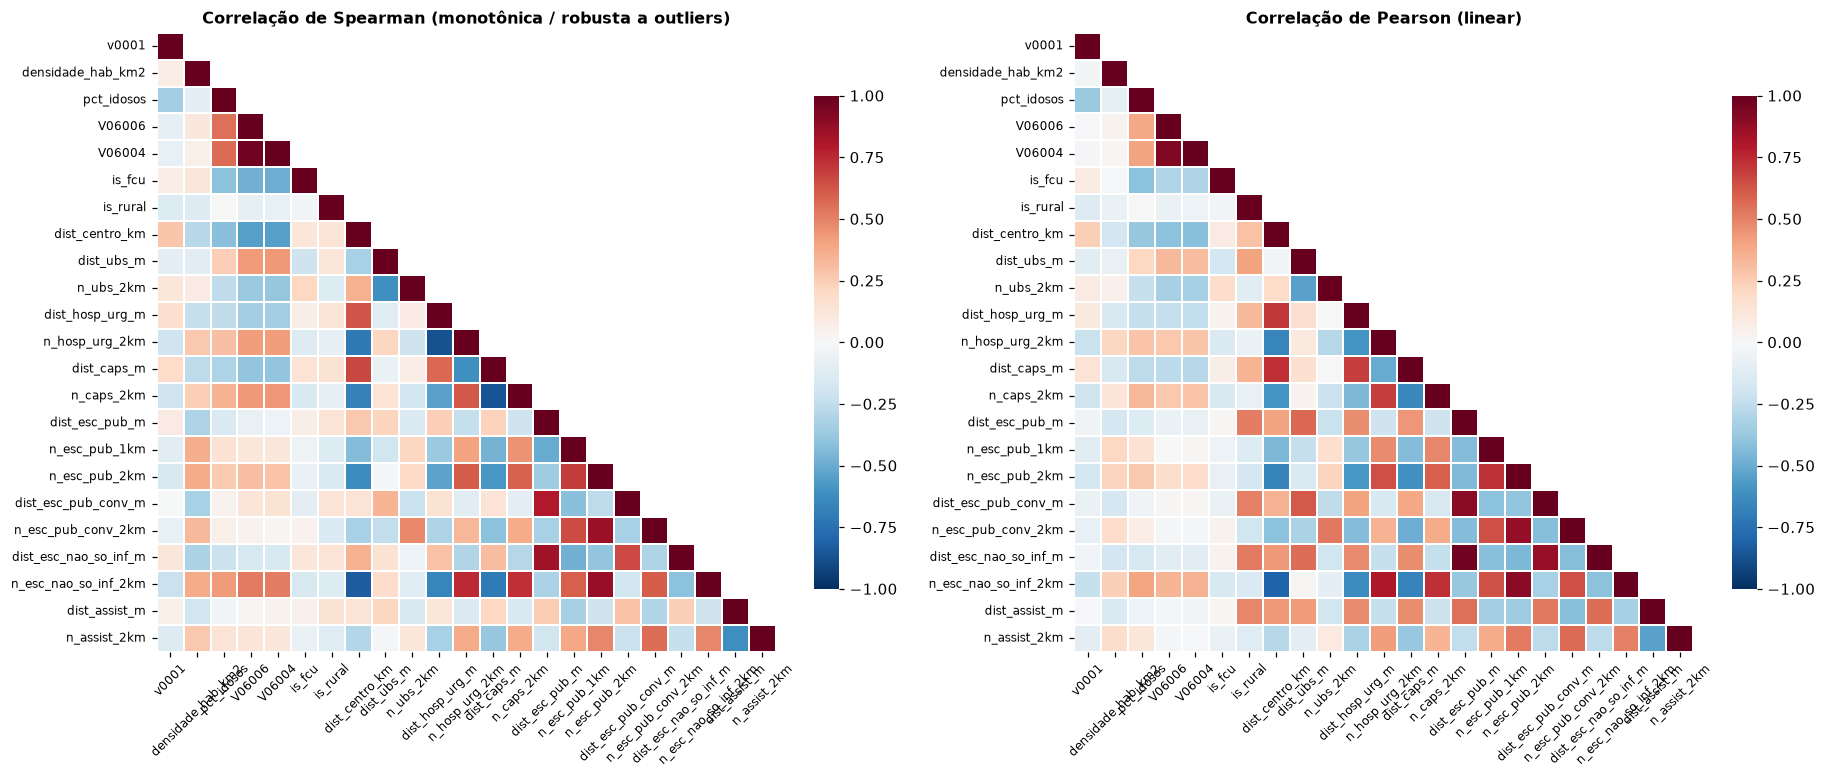


== Correlação de Spearman dos candidatos espaciais com V06006, is_fcu, pct_idosos e densidade ==


,V06006,is_fcu,pct_idosos,densidade_hab_km2
dist_centro_km,-0.547,0.121,-0.421,-0.279
dist_ubs_m,0.425,-0.209,0.247,-0.110
n_ubs_2km,-0.370,0.203,-0.257,0.081
dist_hosp_urg_m,-0.338,0.069,-0.257,-0.234
n_hosp_urg_2km,0.415,-0.127,0.300,0.269
dist_caps_m,-0.397,0.135,-0.305,-0.261
n_caps_2km,0.430,-0.160,0.350,0.245
dist_esc_pub_m,-0.070,0.067,-0.149,-0.307
n_esc_pub_1km,0.119,-0.054,0.155,0.360
n_esc_pub_2km,0.297,-0.067,0.262,0.367


In [8]:
# Monta matriz completa de candidatos demográficos + espaciais (em memória)
base_corr = setores[["CD_SETOR", "v0001", "densidade_hab_km2", "pct_idosos", "V06006", "V06004", "is_fcu", "is_rural"]].copy()
base_corr["is_fcu"] = base_corr["is_fcu"].astype(int)
base_corr["is_rural"] = base_corr["is_rural"].astype(int)

cols_espaciais = [c for c in metricas.columns if c.startswith(("dist_", "n_"))]
df_cand = base_corr.merge(metricas[["CD_SETOR"] + cols_espaciais], on="CD_SETOR").drop(columns=["CD_SETOR"])

corr_spearman = df_cand.corr(method="spearman")
corr_pearson = df_cand.corr(method="pearson")

# Lista pares altamente redundantes (|Spearman| >= 0.80)
pares_red = []
cols = list(df_cand.columns)
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        rho = corr_spearman.iloc[i, j]
        r = corr_pearson.iloc[i, j]
        if abs(rho) >= 0.80:
            pares_red.append({
                "Var_A": cols[i],
                "Var_B": cols[j],
                "Spearman": round(float(rho), 3),
                "Pearson": round(float(r), 3),
            })

df_redundantes = pd.DataFrame(pares_red).sort_values("Spearman", key=lambda s: s.abs(), ascending=False).reset_index(drop=True)
print(f"== Pares com forte redundância (|Spearman| >= 0.80): {len(df_redundantes)} pares ==")
display(df_redundantes)

# Subconjunto focado para visualização legível nos heatmaps (demográficos + principais espaciais)
cols_plot = [
    "v0001", "densidade_hab_km2", "pct_idosos", "V06006", "V06004", "is_fcu", "is_rural",
    "dist_centro_km",
    "dist_ubs_m", "n_ubs_2km",
    "dist_hosp_urg_m", "n_hosp_urg_2km",
    "dist_caps_m", "n_caps_2km",
    "dist_esc_pub_m", "n_esc_pub_1km", "n_esc_pub_2km",
    "dist_esc_pub_conv_m", "n_esc_pub_conv_2km",
    "dist_esc_nao_so_inf_m", "n_esc_nao_so_inf_2km",
    "dist_assist_m", "n_assist_2km",
]

fig, axes = plt.subplots(1, 2, figsize=(17, 7.2))
for ax, mat, titulo in [
    (axes[0], corr_spearman.loc[cols_plot, cols_plot], "Correlação de Spearman (monotônica / robusta a outliers)"),
    (axes[1], corr_pearson.loc[cols_plot, cols_plot], "Correlação de Pearson (linear)"),
]:
    mask = np.triu(np.ones_like(mat, dtype=bool), k=1)
    sns.heatmap(
        mat, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1, center=0,
        square=True, linewidths=0.3, cbar_kws={"shrink": 0.72}, ax=ax,
    )
    ax.set_title(titulo, fontsize=10.5, fontweight="bold")
    ax.tick_params(axis="x", labelsize=8, rotation=45)
    ax.tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

# Correlação direta das variáveis espaciais com renda (V06006), FCU (is_fcu) e densidade
print("\n== Correlação de Spearman dos candidatos espaciais com V06006, is_fcu, pct_idosos e densidade ==")
display(
    corr_spearman.loc[
        [c for c in cols_plot if c.startswith(("dist_", "n_"))],
        ["V06006", "is_fcu", "pct_idosos", "densidade_hab_km2"],
    ].round(3)
)


In [9]:
# 1. Resumo das variáveis cortadas por redundância ou efeito piso (saturação)
cortes = pd.DataFrame([
    {
        "Variavel_cortada": "V06004 (renda média)",
        "Substituida_por": "V06006 (renda mediana)",
        "Evidencia_etapa_5": "Spearman = 0.976 (Pearson = 0.925); média sofre distorção intra-setor (mediana 1.33x, máx 6.77x) e tem mais outliers (116 vs. 87).",
    },
    {
        "Variavel_cortada": "dist_saude_total_m / n_saude_total_*",
        "Substituida_por": "dist_ubs_m + dist_hosp_urg_m (+ dist_caps_m)",
        "Evidencia_etapa_5": "Spearman = 0.810 com dist_ubs_m e mistura níveis com gradientes opostos (UBS mais próxima na periferia; Hospitais/UPA concentrados no centro).",
    },
    {
        "Variavel_cortada": "n_hosp_urg_1km / 2km e n_caps_1km / 2km",
        "Substituida_por": "dist_hosp_urg_m e dist_caps_m",
        "Evidencia_etapa_5": "Efeito piso severo na periferia (82%–94% de zeros em hosp_urg e 88%–97% em CAPS) + forte redundância com distância (|Spearman| = 0.82 a 0.87).",
    },
    {
        "Variavel_cortada": "n_assist_1km / 2km",
        "Substituida_por": "dist_assist_m",
        "Evidencia_etapa_5": "53%–62% de setores zerados em 1 km em todos os anéis (Spearman = -0.849 com dist_assist_m); distância contínua preserva resolução.",
    },
    {
        "Variavel_cortada": "n_esc_todas_* / n_esc_nao_so_inf_* / dist_esc_nao_so_inf_m",
        "Substituida_por": "n_esc_pub_2km e/ou dist_esc_pub_m",
        "Evidencia_etapa_5": "Alta colinearidade entre variantes escolares (Spearman = 0.83 a 0.94); escolas públicas alinham-se melhor ao foco de inclusão (com opção de filtrar is_apenas_educacao_infantil).",
    },
])
print("== Variáveis cortadas (redundância ou saturação) ==")
display(cortes)

# 2. Conferência da correlação entre os geradores recomendados (verifica baixa colinearidade final)
geradores_cols = [
    "V06006", "is_fcu", "densidade_hab_km2", "pct_idosos",
    "dist_ubs_m", "dist_hosp_urg_m", "dist_caps_m",
    "dist_esc_pub_m", "n_esc_pub_2km", "dist_assist_m",
]
print("\n== Matriz de Spearman apenas entre os geradores candidatos finais ==")
display(corr_spearman.loc[geradores_cols, geradores_cols].round(2))

# 3. Catálogo final de geradores recomendados (sem pesos)
catalogo_geradores = pd.DataFrame([
    {
        "Feature": "V06006",
        "Familia": "IBGE (Renda)",
        "Direcao_esperada": "Menor = mais vulnerável (inverter na normalização)",
        "Tratamento_sugerido": "Manter NaN (36 setores); avaliar cap P99 ou transformação suave por skew=2.15",
        "Limitacoes": "Considera apenas responsáveis com rendimento positivo (exclui renda zero).",
    },
    {
        "Feature": "is_fcu",
        "Familia": "IBGE (Território)",
        "Direcao_esperada": "True = mais vulnerável (flag estrutural)",
        "Tratamento_sugerido": "Binária (0/1); 323 setores (mediana R$ 1.250 vs. R$ 3.000 não-FCU)",
        "Limitacoes": "Não captura todos os bolsões de baixa renda fora de FCU (13,7% dos não-FCU têm V06006 <= R$ 1.500); complementar a V06006.",
    },
    {
        "Feature": "densidade_hab_km2",
        "Familia": "IBGE (Demografia)",
        "Direcao_esperada": "Maior = maior demanda potencial",
        "Tratamento_sugerido": "Aplicar log1p() ou winsorize no P99 (~75 mil hab/km²) antes de escalar",
        "Limitacoes": "Assimetria extrema (skew=9.85, máx 491,8 mil hab/km² em micro-setores verticais); 21 setores terrestres têm densidade 0.",
    },
    {
        "Feature": "pct_idosos",
        "Familia": "IBGE (Demografia)",
        "Direcao_esperada": "Maior = maior sensibilidade/prioridade de acessibilidade",
        "Tratamento_sugerido": "Escala quase simétrica (skew=-0.06); manter NaN (74 setores)",
        "Limitacoes": "Correlaciona positivamente com renda/centro (FCUs são mais jovens: 12,4% vs. 25,7%); mede eixo distinto da vulnerabilidade de renda.",
    },
    {
        "Feature": "dist_ubs_m",
        "Familia": "Espacial (Saúde Básica)",
        "Direcao_esperada": "Maior = maior déficit de acesso local",
        "Tratamento_sugerido": "Distância contínua em metros (EPSG:31982); avaliar cap no P95/P99 rural",
        "Limitacoes": "Distância euclidiana (sem barreiras viárias/relevo); gradiente invertido ao centro (periferia tem UBS mais próxima: med. 473 m).",
    },
    {
        "Feature": "dist_hosp_urg_m",
        "Familia": "Espacial (Urgência/Hosp. SUS)",
        "Direcao_esperada": "Maior = maior déficit de acesso a média/alta complexidade",
        "Tratamento_sugerido": "Distância contínua em metros (evita 82%–94% de zeros na periferia)",
        "Limitacoes": "Distância euclidiana; inclui 13 hospitais privados/filantrópicos conveniados ao SUS (sinalizados em tipo_hospital_sus).",
    },
    {
        "Feature": "dist_caps_m",
        "Familia": "Espacial (Saúde Mental)",
        "Direcao_esperada": "Maior = maior déficit de acesso a CAPS",
        "Tratamento_sugerido": "Distância contínua em metros (evita 88%–97% de zeros na periferia)",
        "Limitacoes": "Correlação moderada com dist_hosp_urg_m (avaliar manter se saúde mental for eixo explícito ou simplificar na etapa de pesos).",
    },
    {
        "Feature": "n_esc_pub_2km",
        "Familia": "Espacial (Educação Pública)",
        "Direcao_esperada": "Maior = maior oferta/atração escolar ciclável (2 km)",
        "Tratamento_sugerido": "Contagem em 2 km (apenas 4% zeros na periferia); complementar a dist_esc_pub_m",
        "Limitacoes": "33 escolas públicas sem coordenada ficaram fora da camada espacial; avaliar recorte sem is_apenas_educacao_infantil para foco juvenil.",
    },
    {
        "Feature": "dist_esc_pub_m",
        "Familia": "Espacial (Educação Pública)",
        "Direcao_esperada": "Maior = maior déficit pontual de acesso escolar",
        "Tratamento_sugerido": "Distância contínua em metros (mediana 274 m centro -> 421 m periferia)",
        "Limitacoes": "Mesma limitação das 33 escolas públicas sem coordenada e distância em linha reta.",
    },
    {
        "Feature": "dist_assist_m",
        "Familia": "Espacial (Assistência Social)",
        "Direcao_esperada": "Maior = maior déficit de acesso a CRAS/CREAS/Centro POP",
        "Tratamento_sugerido": "Distância contínua em metros (p90 = 3.190 m na periferia)",
        "Limitacoes": "Base enxuta de 35 pontos (CRAS e CREAS Partenon compartilham coordenada oficial); distância euclidiana.",
    },
])
print("\n== Catálogo de geradores recomendados — Etapa 5 (sem pesos) ==")
display(catalogo_geradores)


== Variáveis cortadas (redundância ou saturação) ==


,Variavel_cortada,Substituida_por,Evidencia_etapa_5
0,V06004 (renda média),V06006 (renda mediana),Spearman = 0.976 (Pearson = 0.925); média sofr...
1,dist_saude_total_m / n_saude_total_*,dist_ubs_m + dist_hosp_urg_m (+ dist_caps_m),Spearman = 0.810 com dist_ubs_m e mistura níve...
2,n_hosp_urg_1km / 2km e n_caps_1km / 2km,dist_hosp_urg_m e dist_caps_m,Efeito piso severo na periferia (82%–94% de ze...
3,n_assist_1km / 2km,dist_assist_m,53%–62% de setores zerados em 1 km em todos os...
4,n_esc_todas_* / n_esc_nao_so_inf_* / dist_esc_...,n_esc_pub_2km e/ou dist_esc_pub_m,Alta colinearidade entre variantes escolares (...



== Matriz de Spearman apenas entre os geradores candidatos finais ==


,V06006,is_fcu,densidade_hab_km2,pct_idosos,dist_ubs_m,dist_hosp_urg_m,dist_caps_m,dist_esc_pub_m,n_esc_pub_2km,dist_assist_m
V06006,1.00,-0.48,0.11,0.55,0.42,-0.34,-0.40,-0.07,0.30,0.02
is_fcu,-0.48,1.00,0.12,-0.41,-0.21,0.07,0.14,0.07,-0.07,0.05
densidade_hab_km2,0.11,0.12,1.00,-0.10,-0.11,-0.23,-0.26,-0.31,0.37,-0.19
pct_idosos,0.55,-0.41,-0.10,1.00,0.25,-0.26,-0.30,-0.15,0.26,-0.04
dist_ubs_m,0.42,-0.21,-0.11,0.25,1.00,-0.11,-0.07,0.22,-0.02,0.22
dist_hosp_urg_m,-0.34,0.07,-0.23,-0.26,-0.11,1.00,0.57,0.25,-0.53,0.12
dist_caps_m,-0.40,0.14,-0.26,-0.30,-0.07,0.57,1.00,0.23,-0.58,0.20
dist_esc_pub_m,-0.07,0.07,-0.31,-0.15,0.22,0.25,0.23,1.00,-0.36,0.25
n_esc_pub_2km,0.30,-0.07,0.37,0.26,-0.02,-0.53,-0.58,-0.36,1.00,-0.21
dist_assist_m,0.02,0.05,-0.19,-0.04,0.22,0.12,0.20,0.25,-0.21,1.00



== Catálogo de geradores recomendados — Etapa 5 (sem pesos) ==


,Feature,Familia,Direcao_esperada,Tratamento_sugerido,Limitacoes
0,V06006,IBGE (Renda),Menor = mais vulnerável (inverter na normaliza...,Manter NaN (36 setores); avaliar cap P99 ou tr...,Considera apenas responsáveis com rendimento p...
1,is_fcu,IBGE (Território),True = mais vulnerável (flag estrutural),Binária (0/1); 323 setores (mediana R$ 1.250 v...,Não captura todos os bolsões de baixa renda fo...
2,densidade_hab_km2,IBGE (Demografia),Maior = maior demanda potencial,Aplicar log1p() ou winsorize no P99 (~75 mil h...,"Assimetria extrema (skew=9.85, máx 491,8 mil h..."
3,pct_idosos,IBGE (Demografia),Maior = maior sensibilidade/prioridade de aces...,Escala quase simétrica (skew=-0.06); manter Na...,Correlaciona positivamente com renda/centro (F...
4,dist_ubs_m,Espacial (Saúde Básica),Maior = maior déficit de acesso local,Distância contínua em metros (EPSG:31982); ava...,Distância euclidiana (sem barreiras viárias/re...
5,dist_hosp_urg_m,Espacial (Urgência/Hosp. SUS),Maior = maior déficit de acesso a média/alta c...,Distância contínua em metros (evita 82%–94% de...,Distância euclidiana; inclui 13 hospitais priv...
6,dist_caps_m,Espacial (Saúde Mental),Maior = maior déficit de acesso a CAPS,Distância contínua em metros (evita 88%–97% de...,Correlação moderada com dist_hosp_urg_m (avali...
7,n_esc_pub_2km,Espacial (Educação Pública),Maior = maior oferta/atração escolar ciclável ...,Contagem em 2 km (apenas 4% zeros na periferia...,33 escolas públicas sem coordenada ficaram for...
8,dist_esc_pub_m,Espacial (Educação Pública),Maior = maior déficit pontual de acesso escolar,Distância contínua em metros (mediana 274 m ce...,Mesma limitação das 33 escolas públicas sem co...
9,dist_assist_m,Espacial (Assistência Social),Maior = maior déficit de acesso a CRAS/CREAS/C...,Distância contínua em metros (p90 = 3.190 m na...,Base enxuta de 35 pontos (CRAS e CREAS Parteno...


### Síntese executiva da Etapa 5 (pronta para a etapa de modelagem/pesos)

- **Escala e assimetria:** `V06006` substitui `V06004` (`ρ = 0,976`, menos distorcida por outliers internos). `densidade_hab_km2` tem `skew = 9,85` por micro-setores verticais (máx. `491,8 mil hab/km²`) e **precisa de `log1p()` ou cap no P99** antes de qualquer normalização linear. `pct_idosos` (`skew = -0,06`) é quase simétrica e atua em eixo independente de renda/FCU.
- **Separação territorial:** `is_fcu` separa nitidamente renda (`R$ 1.250` vs. `R$ 3.000` no urbano não-FCU, `p = 1,16e-139`), densidade (`13,2 mil` vs. `8,9 mil hab/km²`) e estrutura etária (`12,4%` vs. `25,7%` de idosos). `is_rural` permanece apenas como filtro visual/analítico (`21` setores, `0,18%` da população).
- **Família espacial:** para serviços concentrados (`hosp_urg`, `caps`, `assist`), **distância contínua ao mais próximo (`dist_*_m`)** vence contagens em 1–2 km, que colapsam em zero na periferia (`82%` a `97%`). Para serviços capilares (`esc_pub`), `n_esc_pub_2km` (só `4%` de zeros na periferia) mede atração/densidade de oferta, enquanto `dist_esc_pub_m` e `dist_ubs_m` capturam déficits pontuais de acesso.
